# Week 9 — Gradient Boosting *(In-depth analysis I)*

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Target:** `target` = 1 if the loan was **charged off**, 0 if **fully paid** (definition and maturity filter in Week 1).
**Prediction point:** loan issuance, so only origination fields are used.

Questions:
1. Does gradient boosting beat the Week 4 logistic regression and the Week 6 random forest (test ROC-AUC 0.682 for both)?
2. How do **learning rate**, **number of estimators**, **tree depth** and **regularization** control overfitting?
3. How much of the signal comes from LendingClub's own grade and interest rate?

**Model.** `HistGradientBoostingClassifier` (scikit-learn): trees are added one at a time, each fitted to the gradient of the log-loss of the current ensemble (Friedman, 2001); features are binned into at most 255 values, which makes 140,000 rows fast. Missing values and categorical features are handled natively, so — unlike KNN and logistic regression — no imputation, scaling or one-hot encoding is needed.

**Protocol (shared with Weeks 4–8):** the same saved train/test split; tuning by stratified CV on training data only; the threshold maximizes F1 on out-of-fold training predictions; the test set is used once.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy.stats import loguniform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, brier_score_loss, precision_recall_curve, RocCurveDisplay, PrecisionRecallDisplay)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
CV3 = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
N_SEARCH = 20            # randomized-search candidates

scikit-learn 1.9.1


In [2]:
NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "grade", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
for c in CAT:   # categories fixed from the training rows; unseen test levels become missing
    v = df[c].astype("string").fillna("Missing").astype(str)
    df[c] = pd.Categorical(v, categories=sorted(v[df.split == "train"].unique()))
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train["target"].astype(int)
X_te, y_te = test[NUM + CAT], test["target"].astype(int)
print(f"train {X_tr.shape} (rate {y_tr.mean():.2%}) | test {X_te.shape} (rate {y_te.mean():.2%})")

def hgb(**kw):
    base = dict(categorical_features="from_dtype", random_state=RANDOM_STATE, early_stopping=False)
    base.update(kw)
    return HistGradientBoostingClassifier(**base)

def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, score), "PR_AUC(AP)": average_precision_score(y, score),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "threshold": thr}

# Inner train/validation split of the TRAINING rows, used only for the learning-curve diagnostics below
X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=RANDOM_STATE)

def staged_auc(model, every=10):
    """Training and validation ROC-AUC after every `every` boosting iterations."""
    rows = []
    for i, (p_fit, p_val) in enumerate(zip(model.staged_predict_proba(X_fit), model.staged_predict_proba(X_val)), start=1):
        if i % every == 0 or i == 1:
            rows.append({"iteration": i, "train": roc_auc_score(y_fit, p_fit[:, 1]), "validation": roc_auc_score(y_val, p_val[:, 1])})
    return pd.DataFrame(rows)

train (140000, 24) (rate 14.87%) | test (60000, 24) (rate 14.87%)


## 1. Boosting overfits if left alone

Each new tree corrects the remaining errors of the ensemble, so with deep trees, a large learning rate and no penalty, boosting keeps lowering training error long after it has stopped learning anything that generalizes. Two configurations are trained for 500 iterations on 80% of the training rows and scored after every 10 trees on the other 20%:

* **unconstrained** — learning rate 0.3, unlimited depth with up to 255 leaves per tree, leaves as small as 5 loans, no L2 penalty;
* **regularized** — learning rate 0.05, depth 3, at least 200 loans per leaf, L2 penalty 1.0.

In [3]:
configs = {
    "unconstrained (lr 0.3, 255 leaves, min leaf 5, L2 0)": hgb(learning_rate=0.3, max_iter=500, max_leaf_nodes=255, max_depth=None, min_samples_leaf=5, l2_regularization=0.0),
    "regularized (lr 0.05, depth 3, min leaf 200, L2 1)": hgb(learning_rate=0.05, max_iter=500, max_depth=3, min_samples_leaf=200, l2_regularization=1.0),
}
curves = {}
for name, m in configs.items():
    t0 = time.time(); m.fit(X_fit, y_fit); curves[name] = staged_auc(m); print(f"{name}: {time.time()-t0:.0f}s")
overfit_tab = pd.DataFrame({name: {"best validation AUC": c["validation"].max(), "at iteration": int(c.loc[c["validation"].idxmax(), "iteration"]),
                                    "train AUC at 500": c["train"].iloc[-1], "validation AUC at 500": c["validation"].iloc[-1]}
                            for name, c in curves.items()}).T
overfit_tab

unconstrained (lr 0.3, 255 leaves, min leaf 5, L2 0): 15s


regularized (lr 0.05, depth 3, min leaf 200, L2 1): 7s


,best validation AUC,at iteration,train AUC at 500,validation AUC at 500
"unconstrained (lr 0.3, 255 leaves, min leaf 5, L2 0)",0.6590,10.0000,1.0000,0.6252
"regularized (lr 0.05, depth 3, min leaf 200, L2 1)",0.6775,500.0000,0.7110,0.6775


## 2. Learning rate × number of estimators

The learning rate shrinks each tree's contribution. A smaller rate needs more trees to reach the same fit, but each step is more cautious, so the ensemble overshoots less. With depth fixed at 3, the validation curve is traced for three learning rates over 1,500 iterations.

In [4]:
lr_curves = {}
for lr in [0.5, 0.1, 0.02]:
    m = hgb(learning_rate=lr, max_iter=1500, max_depth=3, min_samples_leaf=200, l2_regularization=1.0).fit(X_fit, y_fit)
    lr_curves[lr] = staged_auc(m, every=25)
lr_tab = pd.DataFrame({f"lr={lr}": {"best validation AUC": c["validation"].max(), "trees at best": int(c.loc[c["validation"].idxmax(), "iteration"]),
                                     "validation AUC at 1500": c["validation"].iloc[-1], "train AUC at 1500": c["train"].iloc[-1]}
                       for lr, c in lr_curves.items()}).T
lr_tab

,best validation AUC,trees at best,validation AUC at 1500,train AUC at 1500
lr=0.5,0.6746,25.0000,0.6431,0.8561
lr=0.1,0.6785,475.0000,0.6726,0.7624
lr=0.02,0.6775,"1,500.0000",0.6775,0.7143


## 3. Tree depth

Depth sets how many conditions one tree can chain together, i.e. the order of interaction it can model: depth 1 (stumps) gives an additive model like logistic regression on binned features; depth 3 allows three-way interactions such as *term × FICO × DTI*. Each depth is cross-validated (5-fold) with learning rate 0.05 and **early stopping**: 10% of each training fold is held out and boosting stops when its loss has not improved for 30 rounds.

In [5]:
depth_rows = []
for d in [1, 2, 3, 4, 6, 8, None]:
    m = hgb(learning_rate=0.05, max_iter=2000, max_depth=d, max_leaf_nodes=None if d else 255, min_samples_leaf=20,
            early_stopping=True, validation_fraction=0.1, n_iter_no_change=30)
    r = cross_validate(m, X_tr, y_tr, cv=CV, scoring="roc_auc", return_train_score=True, return_estimator=True, n_jobs=1)
    depth_rows.append({"max_depth": "none (255 leaves)" if d is None else d, "train_AUC": r["train_score"].mean(), "CV_AUC": r["test_score"].mean(),
                       "CV_sd": r["test_score"].std(), "trees (mean)": np.mean([e.n_iter_ for e in r["estimator"]])})
depth_tab = pd.DataFrame(depth_rows).set_index("max_depth"); depth_tab["gap"] = depth_tab["train_AUC"] - depth_tab["CV_AUC"]
depth_tab

,train_AUC,CV_AUC,CV_sd,trees (mean),gap
max_depth,,,,,
1,0.6888,0.6847,0.0019,"1,291.6000",0.0041
2,0.6997,0.6876,0.0012,760.6000,0.0120
3,0.7054,0.6874,0.0011,375.0000,0.0179
4,0.7195,0.6871,0.0013,326.6000,0.0324
6,0.7436,0.6858,0.0022,148.0000,0.0578
8,0.8067,0.6829,0.0020,130.8000,0.1238
none (255 leaves),0.8794,0.6797,0.0017,94.4000,0.1996


## 4. Randomized search over the regularization hyperparameters

* `learning_rate` — shrinkage of each tree (log-uniform 0.01–0.3).
* `max_depth`, `max_leaf_nodes` — size of each tree.
* `min_samples_leaf` — minimum loans per leaf; larger values stop a leaf from describing a handful of borrowers.
* `l2_regularization` — L2 penalty on leaf values, which pulls small-leaf predictions toward zero.
* `max_features` — share of features each split may consider (feature subsampling, as in random forests), which decorrelates trees.
* The **number of trees** is not searched: early stopping chooses it inside every fit (up to 2,000).

20 candidates × 3 stratified folds, scored on ROC-AUC (average precision also recorded).

In [6]:
param_dist = {"learning_rate": loguniform(0.01, 0.3), "max_depth": [2, 3, 4, 5, 6, 8],
              "max_leaf_nodes": [7, 15, 31, 63], "min_samples_leaf": [20, 100, 300, 1000],
              "l2_regularization": loguniform(1e-3, 10), "max_features": [0.5, 0.8, 1.0]}
search = RandomizedSearchCV(hgb(max_iter=2000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30),
                            param_dist, n_iter=N_SEARCH, scoring={"roc_auc": "roc_auc", "ap": "average_precision"}, refit="roc_auc",
                            cv=CV3, return_train_score=True, random_state=RANDOM_STATE, n_jobs=1)
t0 = time.time(); search.fit(X_tr, y_tr); print(f"Randomized search: {time.time()-t0:.0f}s")
print("Best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()})
print(f"CV ROC-AUC {search.best_score_:.4f} | trees chosen by early stopping in refit: {search.best_estimator_.n_iter_}")
sr = pd.DataFrame(search.cv_results_)
cols = ["param_" + p for p in param_dist] + ["mean_train_roc_auc", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_ap"]
sr[cols].sort_values("mean_test_roc_auc", ascending=False).head(10)

Randomized search: 313s
Best params: {'l2_regularization': np.float64(0.0202), 'learning_rate': np.float64(0.0696), 'max_depth': 5, 'max_features': 0.5, 'max_leaf_nodes': 15, 'min_samples_leaf': 1000}
CV ROC-AUC 0.6878 | trees chosen by early stopping in refit: 219


,param_learning_rate,param_max_depth,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,param_max_features,mean_train_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_ap
13,0.0696,5,15,1000,0.0202,0.5000,0.7202,0.6878,0.0023,0.2664
14,0.1270,6,7,1000,2.3886,0.8000,0.7079,0.6878,0.0026,0.2668
1,0.0140,4,63,1000,0.0607,0.5000,0.7082,0.6877,0.0025,0.2672
12,0.0383,5,31,1000,0.0630,0.8000,0.7201,0.6876,0.0022,0.2668
7,0.0463,3,63,100,0.5263,0.5000,0.7052,0.6874,0.0025,0.2674
4,0.0269,4,15,1000,0.0534,1.0000,0.7090,0.6873,0.0025,0.2670
6,0.0575,2,7,300,0.0063,1.0000,0.7005,0.6872,0.0025,0.2666
17,0.1194,2,7,100,0.6721,1.0000,0.7021,0.6870,0.0025,0.2664
16,0.0422,2,31,300,0.0012,1.0000,0.6997,0.6870,0.0025,0.2665
2,0.0107,3,15,100,0.6797,0.8000,0.7047,0.6870,0.0024,0.2670


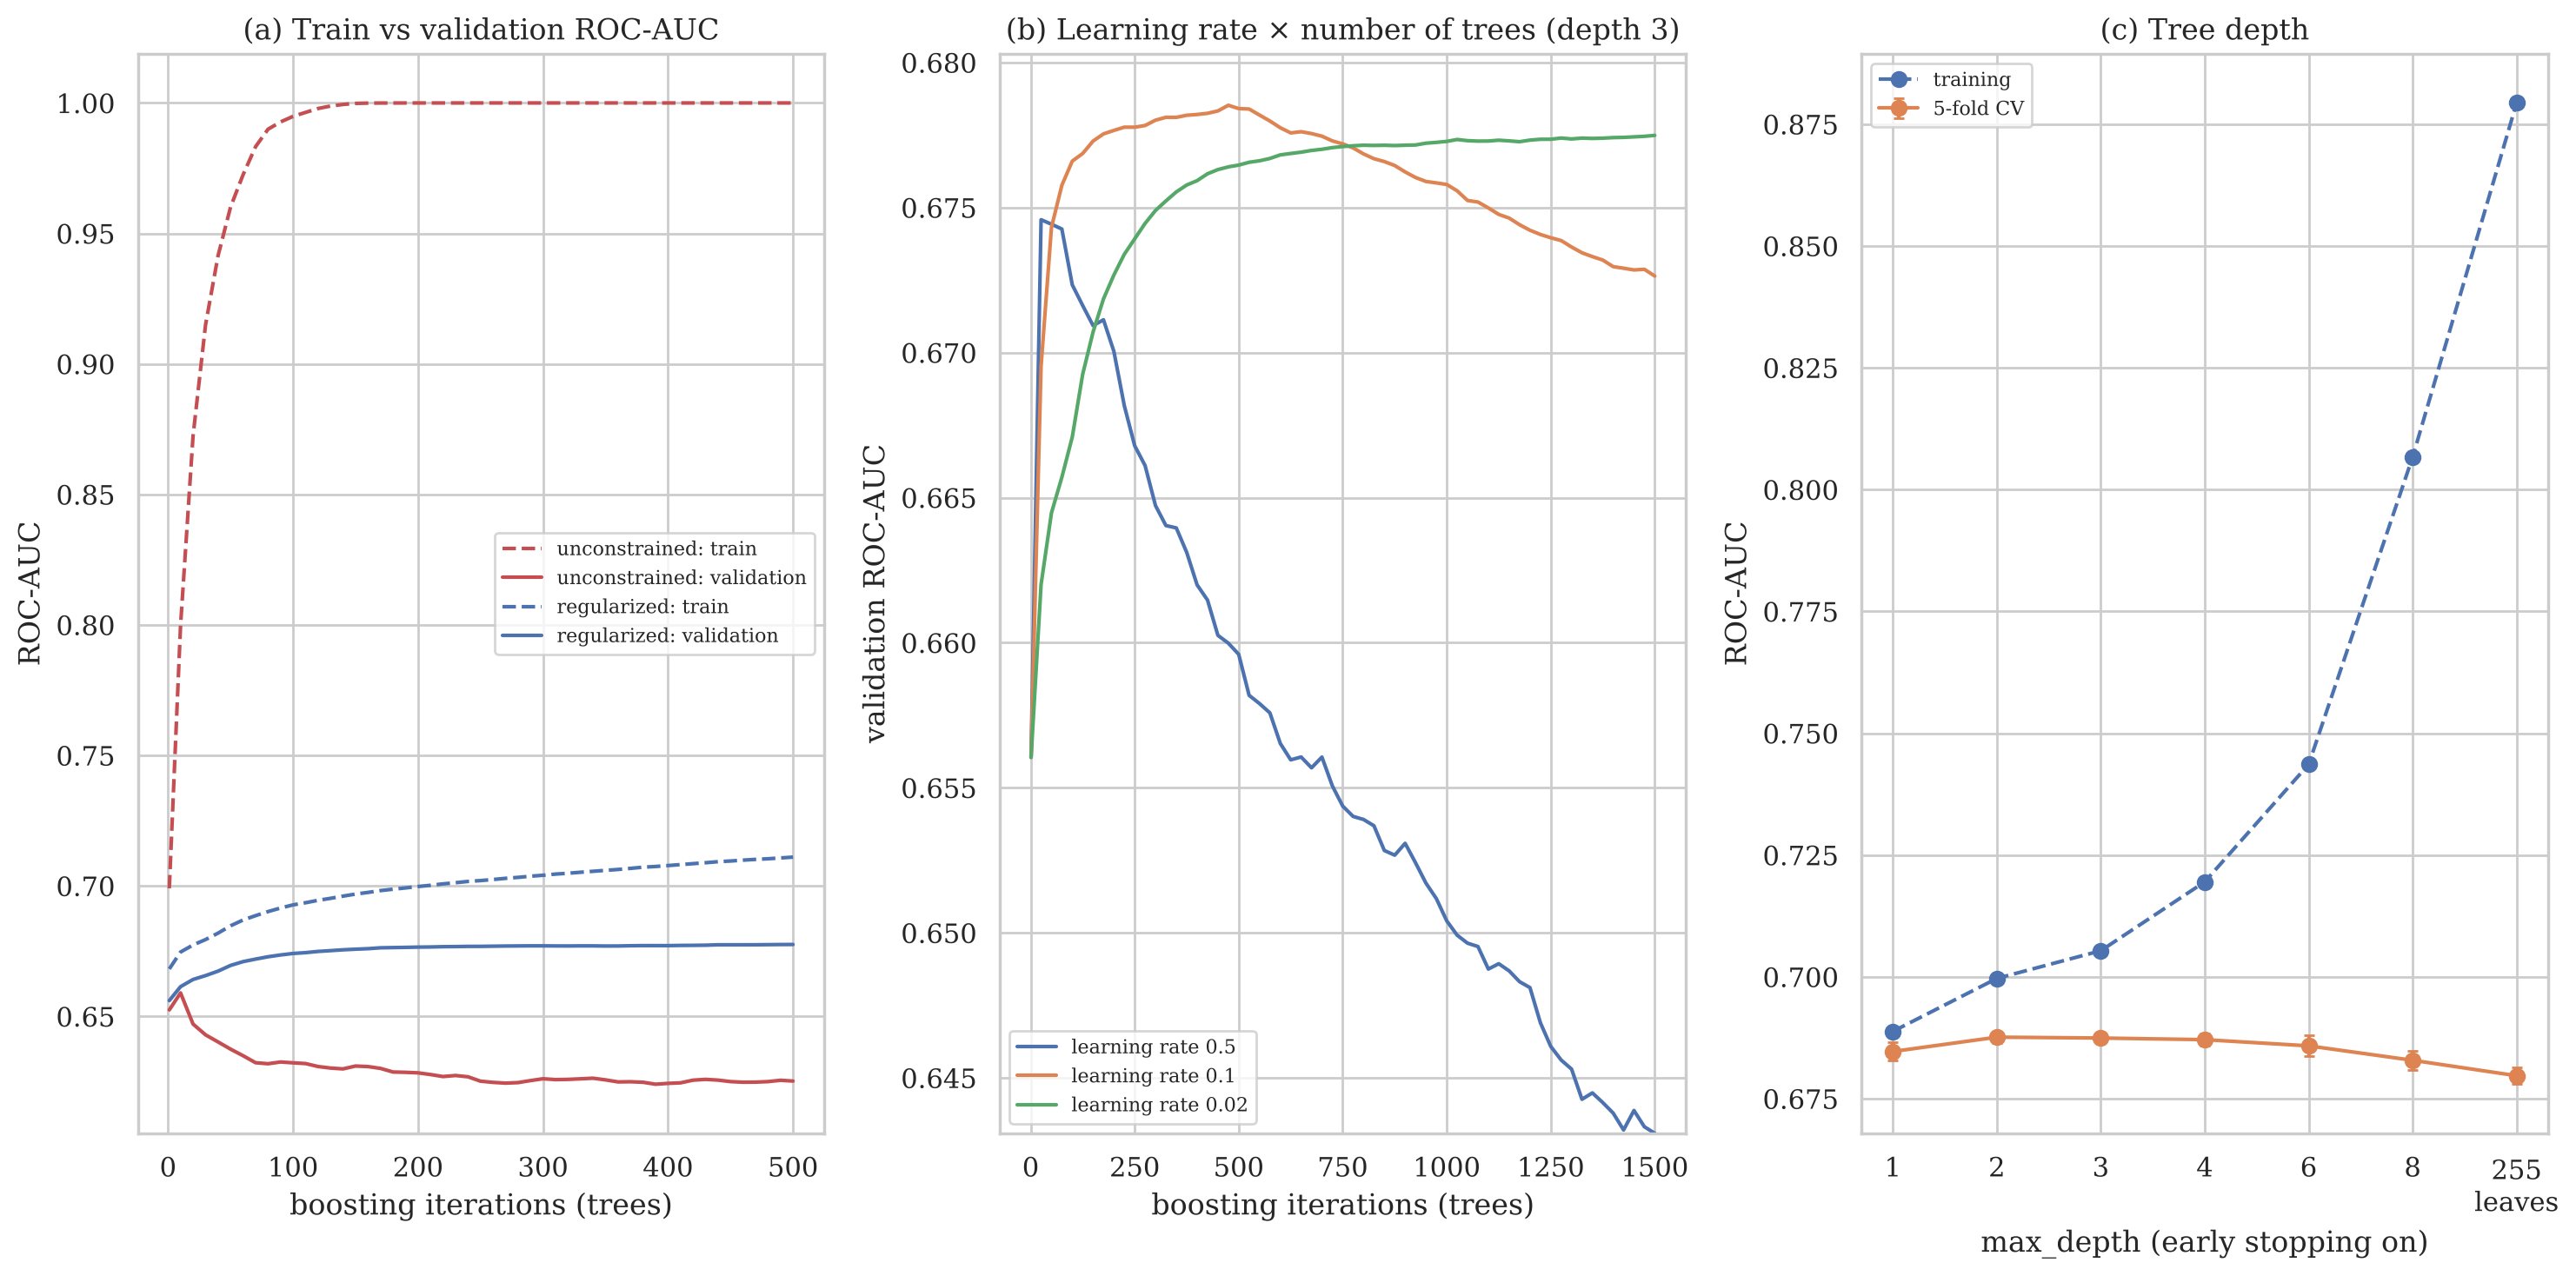

In [7]:
# Figure for the report: (a) overfitting demonstration, (b) learning rate curves, (c) depth
fig, axes = plt.subplots(1, 3, figsize=(15, 7.5))
for (name, c), col in zip(curves.items(), ["#C44E52", "#4C72B0"]):
    short = name.split(" (")[0]
    axes[0].plot(c["iteration"], c["train"], ls="--", c=col, label=f"{short}: train")
    axes[0].plot(c["iteration"], c["validation"], c=col, label=f"{short}: validation")
axes[0].set(xlabel="boosting iterations (trees)", ylabel="ROC-AUC", title="(a) Train vs validation ROC-AUC"); axes[0].legend(fontsize=8)
for lr, c in lr_curves.items():
    axes[1].plot(c["iteration"], c["validation"], label=f"learning rate {lr}")
axes[1].set(xlabel="boosting iterations (trees)", ylabel="validation ROC-AUC", title="(b) Learning rate × number of trees (depth 3)"); axes[1].legend(fontsize=8)
lo = min(c["validation"].min() for c in lr_curves.values()); axes[1].set_ylim(max(lo, 0.6), None)
x = np.arange(len(depth_tab))
axes[2].plot(x, depth_tab["train_AUC"], marker="o", ls="--", label="training")
axes[2].errorbar(x, depth_tab["CV_AUC"], yerr=depth_tab["CV_sd"], marker="o", capsize=2, label="5-fold CV")
axes[2].set_xticks(x, ["255\nleaves" if "none" in str(i) else str(i) for i in depth_tab.index]); axes[2].set(xlabel="max_depth (early stopping on)", ylabel="ROC-AUC", title="(c) Tree depth"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_gb_overfitting_tuning.png", dpi=200); plt.show()

## 5. Threshold (training data only) and held-out test evaluation

In [8]:
best_gb = search.best_estimator_
oof = cross_val_predict(best_gb, X_tr, y_tr, cv=CV, method="predict_proba", n_jobs=1)[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, oof)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
THR = float(thr[np.nanargmax(f1[:-1])])
score_te = best_gb.predict_proba(X_te)[:, 1]
score_tr = best_gb.predict_proba(X_tr)[:, 1]
print(f"F1-optimal threshold (out-of-fold): {THR:.3f}")
print(f"Gradient boosting — train ROC-AUC {roc_auc_score(y_tr, score_tr):.4f} | OOF {roc_auc_score(y_tr, oof):.4f} | CV (search) {search.best_score_:.4f} | test {roc_auc_score(y_te, score_te):.4f}")

wk4 = pd.read_parquet(RES_DIR / "week4_logistic_test_scores.parquet").set_index("id").loc[test["id"].values]
assert (wk4["y"].values == y_te.values).all()
gb_row = {"model": "Gradient boosting (Wk 9)", **metrics(y_te, score_te, THR), "Brier": brier_score_loss(y_te, score_te)}
prev = pd.read_csv(RES_DIR / "final_model_comparison.csv")
comparison = pd.concat([pd.DataFrame([gb_row]), prev]).set_index("model").sort_values("ROC_AUC", ascending=False)
comparison.to_csv(RES_DIR / "final_model_comparison_with_gb.csv")
comparison

F1-optimal threshold (out-of-fold): 0.170
Gradient boosting — train ROC-AUC 0.7107 | OOF 0.6887 | CV (search) 0.6878 | test 0.6892


,ROC_AUC,PR_AUC(AP),accuracy,precision,recall,F1,threshold,Brier
model,,,,,,,,
Gradient boosting (Wk 9),0.6892,0.2671,0.6727,0.2445,0.5748,0.3430,0.1697,0.1193
Random forest (Wk 6),0.6823,0.2617,0.6575,0.2355,0.5804,0.3350,0.1706,0.1198
Logistic regression (Wk 4),0.6821,0.2609,0.6639,0.2391,0.5777,0.3382,0.1671,0.1198
Linear SVM (Wk 5),0.6803,0.2600,0.6593,0.2368,0.5813,0.3365,-0.6481,NaN
RBF SVM (Wk 5),0.6757,0.2538,0.6700,0.2381,0.5545,0.3331,0.4954,NaN
Decision tree (Wk 6),0.6670,0.2443,0.6662,0.2319,0.5387,0.3243,0.1686,0.1211


In [9]:
# Paired bootstrap: is the AUC gain over logistic regression larger than sampling noise? (same 60,000 test loans)
rng = np.random.default_rng(RANDOM_STATE)
yv, s_gb, s_lr = y_te.values, score_te, wk4["score"].values
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(yv), len(yv))
    diffs.append(roc_auc_score(yv[i], s_gb[i]) - roc_auc_score(yv[i], s_lr[i]))
diffs = np.array(diffs)
AUC_DIFF = roc_auc_score(yv, s_gb) - roc_auc_score(yv, s_lr)
CI = np.percentile(diffs, [2.5, 97.5])
print(f"GB − LR test ROC-AUC = {AUC_DIFF:+.4f} (95% bootstrap CI {CI[0]:+.4f} to {CI[1]:+.4f})")

GB − LR test ROC-AUC = +0.0070 (95% bootstrap CI +0.0052 to +0.0087)


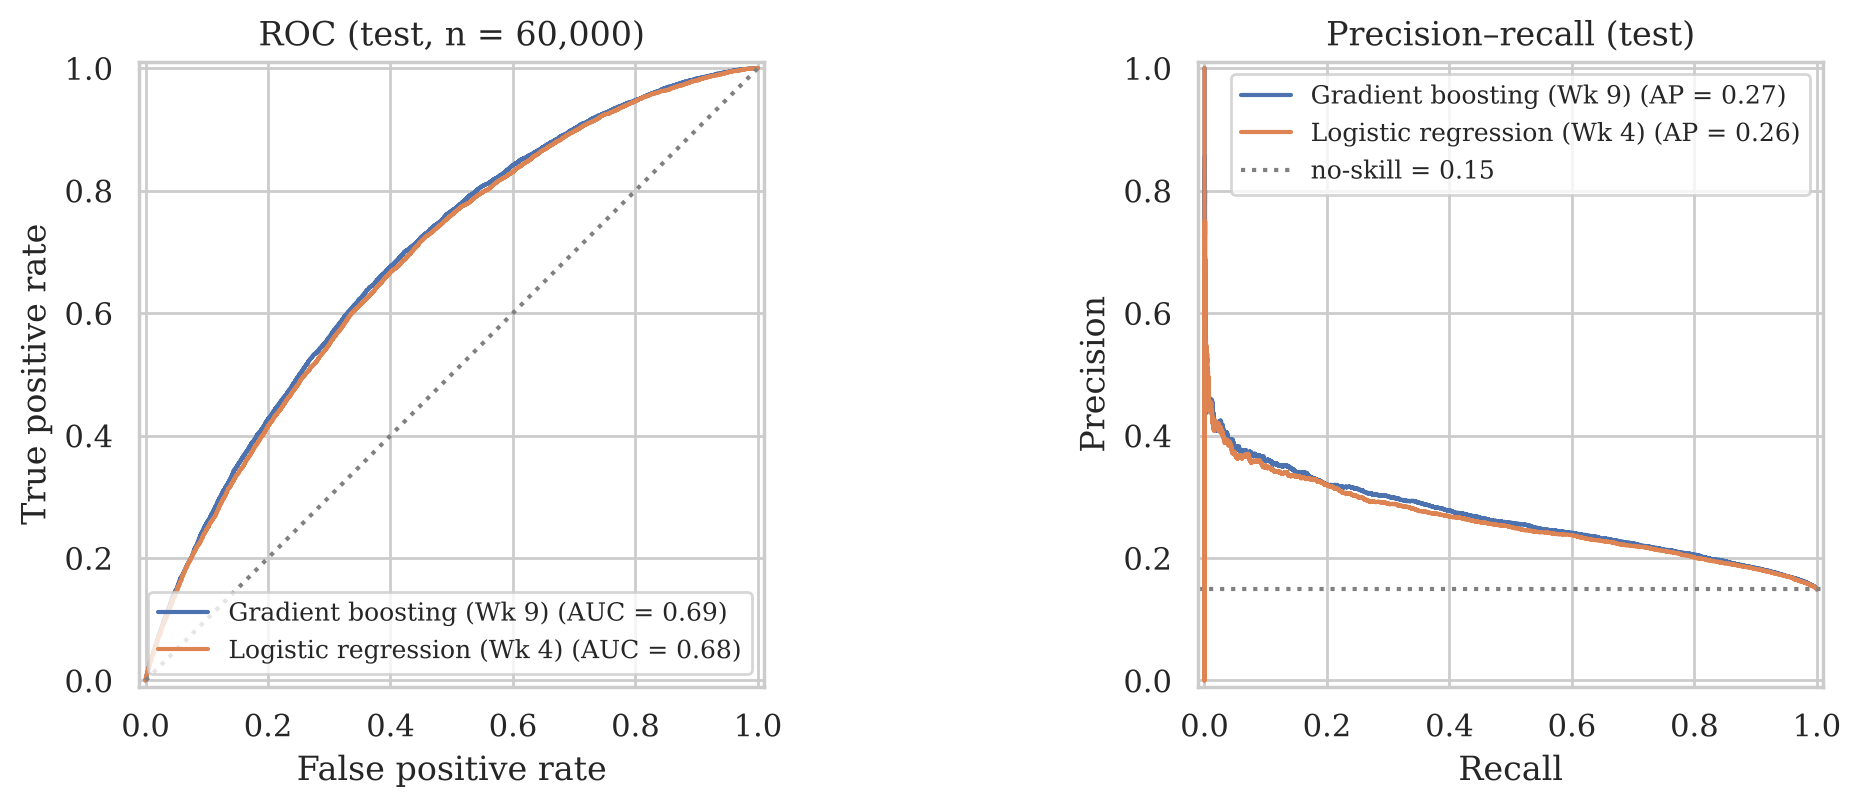

In [10]:
# Figure for the report: ROC and PR curves, GB vs logistic regression, plus confusion counts at each threshold
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
lr_thr = float(wk4["threshold"].iloc[0])
for name, s in [("Gradient boosting (Wk 9)", s_gb), ("Logistic regression (Wk 4)", s_lr)]:
    RocCurveDisplay.from_predictions(y_te, s, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_predictions(y_te, s, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], ls=":", c="grey"); axes[0].set(title=f"ROC (test, n = {len(y_te):,})", xlabel="False positive rate", ylabel="True positive rate")
axes[1].axhline(y_te.mean(), ls=":", c="grey", label=f"no-skill = {y_te.mean():.2f}")
axes[1].set(title="Precision–recall (test)", xlabel="Recall", ylabel="Precision"); axes[1].legend(fontsize=9)
axes[0].legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_gb_vs_lr_test.png", dpi=200); plt.show()

## 6. Which features drive the model? Permutation importance (test set)

Permutation importance shuffles one feature at a time and measures the drop in test ROC-AUC. Unlike gain-based importance it is measured on held-out data and is not inflated for features with many split points. Correlated features (grade and interest rate) share credit: shuffling one leaves the other, so each looks less important than the pair.

In [11]:
Xi, _, yi, _ = train_test_split(X_te, y_te, train_size=20_000, stratify=y_te, random_state=RANDOM_STATE)
t0 = time.time()
pi = permutation_importance(best_gb, Xi, yi, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
print(f"Permutation importance: {time.time()-t0:.0f}s on {len(Xi):,} test loans")
imp = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X_te.columns).sort_values("mean", ascending=False)
imp.head(15)

Permutation importance: 17s on 20,000 test loans


,mean,sd
int_rate,0.0227,0.0020
grade,0.0164,0.0014
log_annual_inc,0.0104,0.0012
loan_amnt,0.0094,0.0013
dti,0.0070,0.0006
fico,0.0065,0.0020
log_revol_bal,0.0053,0.0006
emp_length_yrs,0.0050,0.0006
open_acc,0.0044,0.0005
inq_last_6mths,0.0029,0.0005


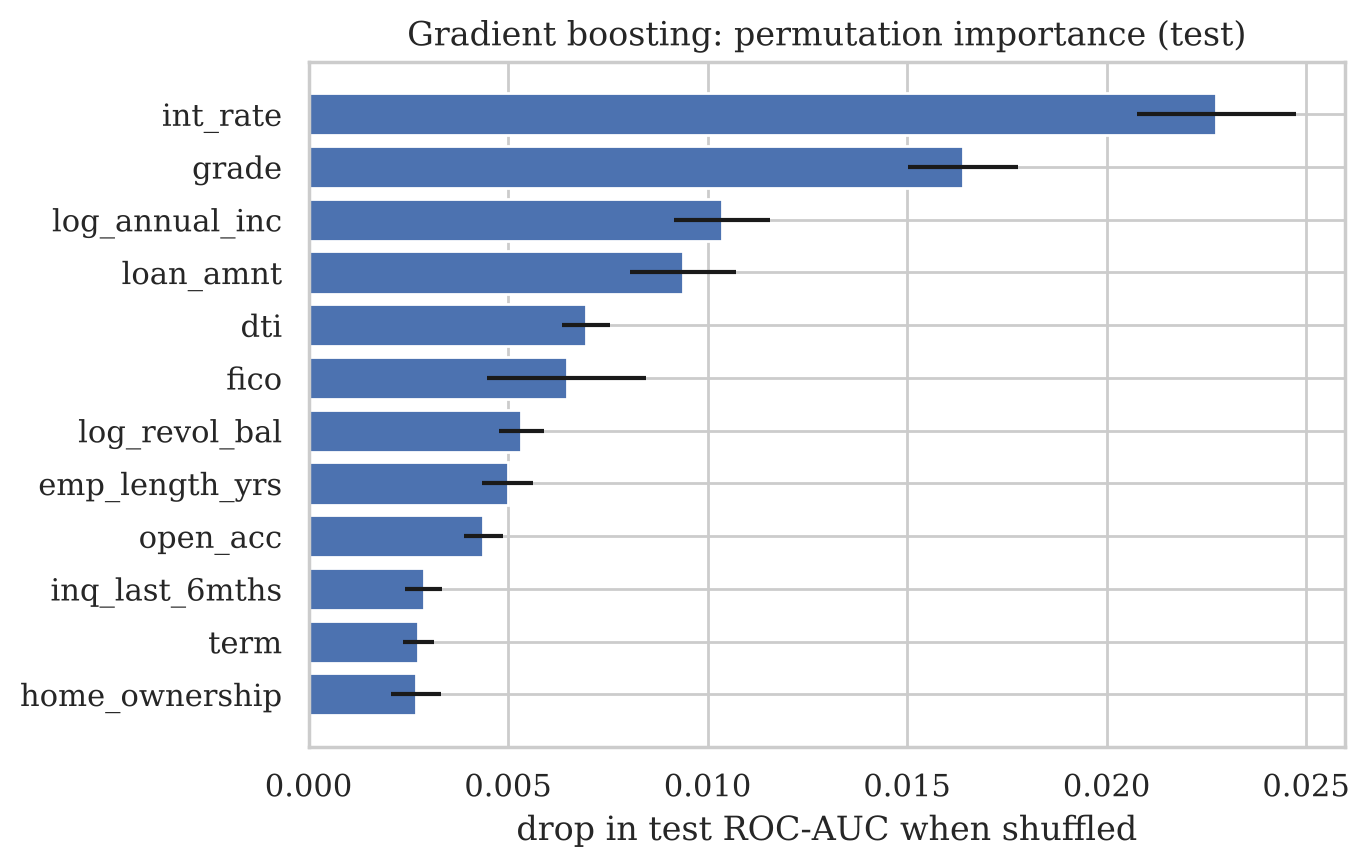

In [12]:
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.index, top["mean"], xerr=top["sd"], color="#4C72B0")
ax.set(xlabel="drop in test ROC-AUC when shuffled", title="Gradient boosting: permutation importance (test)")
plt.tight_layout(); plt.savefig(FIG_DIR / "week9_permutation_importance.png", dpi=200); plt.show()

## 7. How much depends on LendingClub's own grade and rate?

`grade` and `int_rate` are LendingClub's assessment of the same risk. Refitting the tuned model without them shows how much a lender could recover from the borrower's own characteristics.

In [13]:
no_lc = [c for c in NUM + CAT if c not in ("grade", "int_rate")]
gb_no_lc = hgb(**{**search.best_estimator_.get_params(), "categorical_features": "from_dtype"}).fit(X_tr[no_lc], y_tr)
auc_no_lc = roc_auc_score(y_te, gb_no_lc.predict_proba(X_te[no_lc])[:, 1])
auc_lc_only = roc_auc_score(y_te, hgb(learning_rate=0.05, max_iter=300, max_depth=3).fit(X_tr[["grade", "int_rate", "term"]], y_tr).predict_proba(X_te[["grade", "int_rate", "term"]])[:, 1])
ablation = pd.Series({"all features": roc_auc_score(y_te, score_te), "without grade and int_rate": auc_no_lc,
                      "grade + int_rate + term only": auc_lc_only}, name="test ROC-AUC")
ablation.to_frame()

,test ROC-AUC
all features,0.6892
without grade and int_rate,0.6757
grade + int_rate + term only,0.6647


In [14]:
pd.DataFrame({"id": test["id"].values, "y": y_te.values, "score": score_te, "threshold": THR}).to_parquet(RES_DIR / "week9_gb_test_scores.parquet", index=False)
flagged = (score_te >= THR)
summary = {"best_params": str(search.best_params_), "n_trees": best_gb.n_iter_, "cv_auc": search.best_score_,
           "train_auc": roc_auc_score(y_tr, score_tr), "oof_auc": roc_auc_score(y_tr, oof), "test_auc": roc_auc_score(y_te, score_te),
           "test_ap": average_precision_score(y_te, score_te), "threshold": THR, "flag_share": flagged.mean(), "n_flagged": int(flagged.sum()),
           "auc_diff_vs_lr": AUC_DIFF, "ci_lo": CI[0], "ci_hi": CI[1], "auc_no_lc": auc_no_lc, "auc_lc_only": auc_lc_only}
pd.Series(summary).to_csv(RES_DIR / "week9_summary.csv")
pd.Series(summary)

best_params       {'l2_regularization': np.float64(0.02023778954...
n_trees                                                         219
cv_auc                                                       0.6878
train_auc                                                    0.7107
oof_auc                                                      0.6887
test_auc                                                     0.6892
test_ap                                                      0.2671
threshold                                                    0.1697
flag_share                                                   0.3495
n_flagged                                                     20972
auc_diff_vs_lr                                               0.0070
ci_lo                                                        0.0052
ci_hi                                                        0.0087
auc_no_lc                                                    0.6757
auc_lc_only                                     

## 8. Conclusions

**Overfitting demonstration.** Unconstrained boosting (learning rate 0.3, up to 255 leaves, leaves of 5 loans, no L2) peaked at validation AUC 0.659 after only 10 trees, then fell to 0.625 by 500 trees while training AUC reached 1.000. The regularized configuration (0.05, depth 3, leaves ≥ 200, L2 = 1) was still improving at 500 trees (validation 0.678; training 0.711).

**Learning rate × trees.** Higher learning rates peak sooner and decay faster: 0.5 peaked at 25 trees (0.675) and fell to 0.643 by 1,500; 0.1 peaked at 475 trees (0.679); 0.02 was still rising at 1,500 (0.678). Learning rate and number of trees trade off, which is why the number of trees is set by early stopping rather than tuned.

**Depth.** With early stopping, CV AUC was flat from depth 2 to 4 (0.687) and fell slowly beyond (0.680 for 255-leaf trees), while the train–CV gap grew from 0.004 (stumps) to 0.200. Stumps (an additive model, 0.685) already captured most of the signal; depth 2 added 0.003, so interactions exist but are weak.

**Tuning.** The randomized search (20 candidates × 3 folds) chose learning rate 0.070, depth 5 with at most 15 leaves, at least 1,000 loans per leaf, L2 = 0.020, and 50% of features per split; early stopping kept 219 trees (CV AUC 0.688). The top 10 candidates were within 0.001 of each other, and all had large minimum leaf sizes or shallow trees: regularization mattered more than any single setting.

**Test result.** Train, out-of-fold and test ROC-AUC were 0.711, 0.689 and 0.689. The train–test gap of 0.022 is larger than logistic regression's (0.003) but the out-of-fold and test scores agree, so the model generalizes. Test ROC-AUC 0.689 vs. 0.682 for logistic regression: +0.0070 (95% paired bootstrap CI +0.0052 to +0.0087), the first model in the project to beat logistic regression by more than sampling noise. Flagging the same 21,555 loans as the Week 4 model, it catches 5,232 charge-offs instead of 5,153.

**Grade and rate.** Permutation importance ranks interest rate (0.023) and grade (0.016) first, then income, loan amount, DTI and FICO. Without grade and rate, test AUC falls to 0.676 — still close to logistic regression *with* them — while grade, rate and term alone reach 0.665. Most of LendingClub's pricing can be recovered from the borrower's own characteristics.

## Source for this week (shared on Yellowdig)

scikit-learn developers. (n.d.). *Ensembles: Gradient boosting, random forests, bagging, voting, stacking*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/ensemble.html

**Why it is high quality:** It documents exactly the estimator used here — binning, native missing-value and categorical support, early stopping by default above 10,000 samples — and the shrinkage (learning rate) and subsampling regularization for gradient boosting, with references to Friedman (2001).